**10 Monkeys Dataset Classification using a Convolutional Neural Newtwork - By Ehsan Fijhas**

In [1]:
!pip install -q torchinfo

In [2]:
import torch
import torch.nn as nn
from torch.optim import Adam
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchinfo import summary
from torch.utils.tensorboard import SummaryWriter

import torchvision
from torchvision import datasets
from torchvision.transforms import v2 as transforms
from torchvision.ops import Conv2dNormActivation

from dataclasses import dataclass
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
import seaborn as sn

import matplotlib.pyplot as plt
import time
import numpy as np
import random
import warnings
import os
from tqdm import tqdm

import pandas as pd

%matplotlib inline
warnings.filterwarnings("ignore")

In [3]:
def set_seed(seed):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)

  if torch.cuda.is_available():
   torch.cuda.manual_seed(seed)
   torch.cuda.manual_seed_all(seed)
   torch.backends.cudnn.deterministic = True
   torch.backends.cudnn.benchmark = True
set_seed(42)

In [4]:
!wget -q "https://www.dropbox.com/s/45jdd8padeyjq6t/10_Monkey_Species.zip?dl=1" -O "10_Monkey_Species.zip"

In [5]:
!unzip -q "10_Monkey_Species.zip"

In [6]:
@dataclass(frozen=True)
class TrainingConfig:
  batch_size: int = 32
  num_epochs: int = 50
  learning_rate: float = 1e-4

  log_interval: int = 1
  test_interval: int = 1
  data_root: int = "./"
  num_workers: int = 5
  device: str = "cuda"

train_config = TrainingConfig()
DEVICE = torch.device("cuda") if torch.cuda.is_available() else "cpu"
print("Available Device: ", DEVICE)

Available Device:  cuda


In [7]:
train_root = os.path.join("10_Monkey_Species", "training", "training")
val_root = os.path.join("10_Monkey_Species", "validation", "validation")

In [8]:
df = pd.read_csv(os.path.join("10_Monkey_Species","monkey_labels.txt"), sep=",", header=None)
df.columns = ["Label", "Latin Name", "Common Name", "Train Images", "Validation Images"]
df['Latin Name'] = df['Latin Name'].str.replace("\t", " ")
df[1:]

,Label,Latin Name,Common Name,Train Images,Validation Images
1,n0,alouatta_palliata,mantled_howler,131,26
2,n1,erythrocebus_patas,patas_monkey,139,28
3,n2,cacajao_calvus,bald_uakari,137,27
4,n3,macaca_fuscata,japanese_macaque,152,30
5,n4,cebuella_pygmea,pygmy_marmoset,131,26
6,n5,cebus_capucinus,white_headed_capuchin,141,28
7,n6,mico_argentatus,silvery_marmoset,132,26
8,n7,saimiri_sciureus,common_squirrel_monkey,142,28
9,n8,aotus_nigriceps,black_headed_night_monkey,133,27
10,n9,trachypithecus_johnii,nilgiri_langur,132,26


In [9]:
mean = [0.4368, 0.4336, 0.3294]
std = [0.2457, 0.2413, 0.2447]

img_size = (224, 224)

preprocess = transforms.Compose(
    [
      transforms.Resize(img_size, antialias=True),
      transforms.ToTensor()
    ]
)

In [10]:
from math import degrees
common_transforms = transforms.Compose(
    [
       preprocess,
       transforms.Normalize(mean=mean, std=std)
    ]
)

train_transforms = transforms.Compose(
    [
        preprocess,
        transforms.RandomHorizontalFlip(),

        transforms.RandomErasing(p=0.4),
        transforms.RandomApply([
          transforms.RandomAffine(degrees=(30,70), translate=(0.1, 0.3), scale=(0.5,0.75)),
        ], p=0.1),

        transforms.Normalize(mean=mean, std=std)
    ]
)

In [11]:
train_data = datasets.ImageFolder(root=train_root, transform = train_transforms)
val_data = datasets.ImageFolder(root=val_root, transform=common_transforms)

In [12]:
train_loader = DataLoader(
    train_data,
    shuffle = True,
    batch_size= train_config.batch_size,
    num_workers = train_config.num_workers
)

val_loader = DataLoader(
    val_data,
    shuffle = True,
    batch_size = train_config.batch_size,
    num_workers = train_config.num_workers
)

In [13]:
class_mapping = {
    0: "mantled_howler",
    1: "patas_monkey",
    2: "bald_uakari",
    3: "japanese_macaque",
    4: "pygmy_marmoset",
    5: "white_headed_capuchin",
    6: "silvery_marmoset",
    7: "common_squirrel_monkey",
    8: "black_headed_night_monkey",
    9: "nilgiri_langur"
}

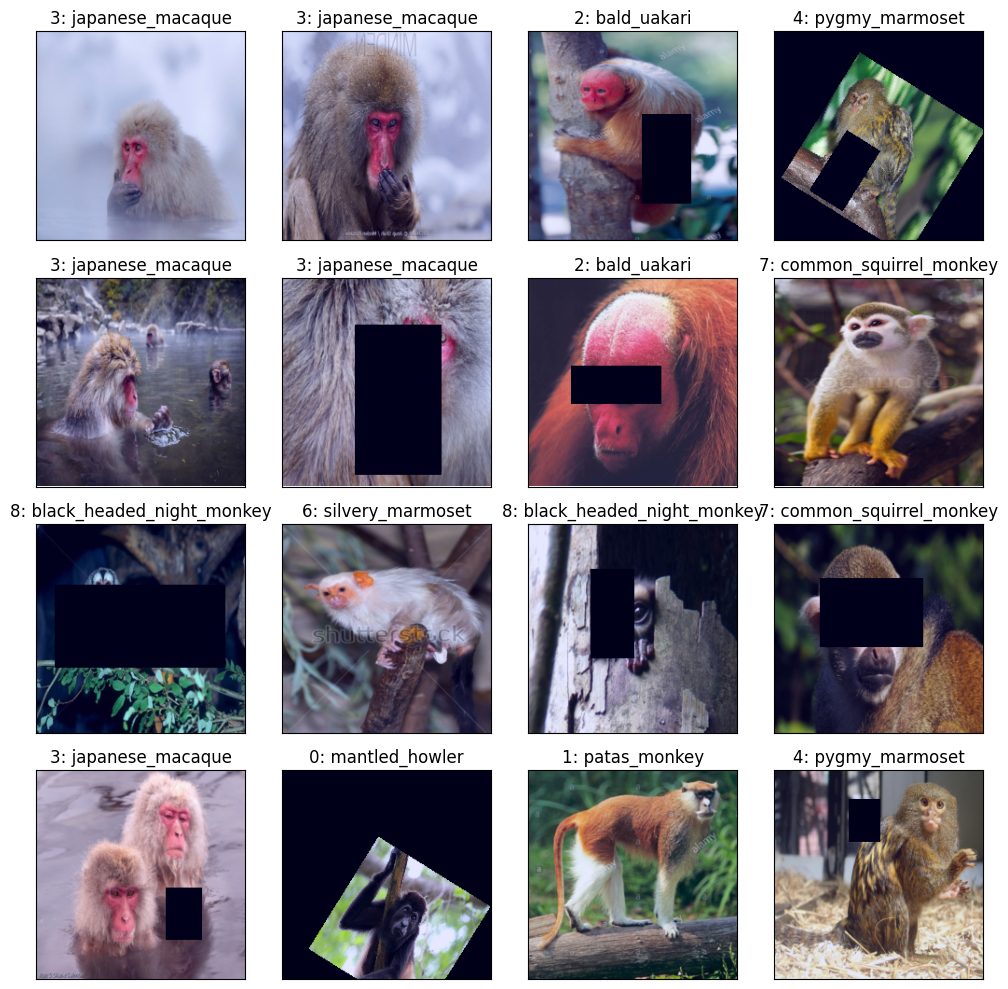

In [14]:
def visualize_images(dataloader, num_images = 20):
    fig = plt.figure(figsize=(10,10))
    images, labels = next(iter(dataloader))

    num_rows = 4
    num_cols = int(np.ceil((num_images / num_rows)))

    for idx in range(min(num_images, len(images))):
        image, label = images[idx], labels[idx]


        ax = fig.add_subplot(num_rows, num_cols, idx+1, xticks = [], yticks = [])

        image = image.permute(1,2,0)

        #Normalize the image to [0,1] to display

        image = (image - image.min()) / (image.max() - image.min())
        ax.imshow(image, cmap="gray")  # remove the batch dimension
        ax.set_title(f"{label.item()}: {class_mapping[label.item()]}")

    fig.tight_layout()
    plt.show()

visualize_images(train_loader, num_images = 16)

**Implementing CNN Model**


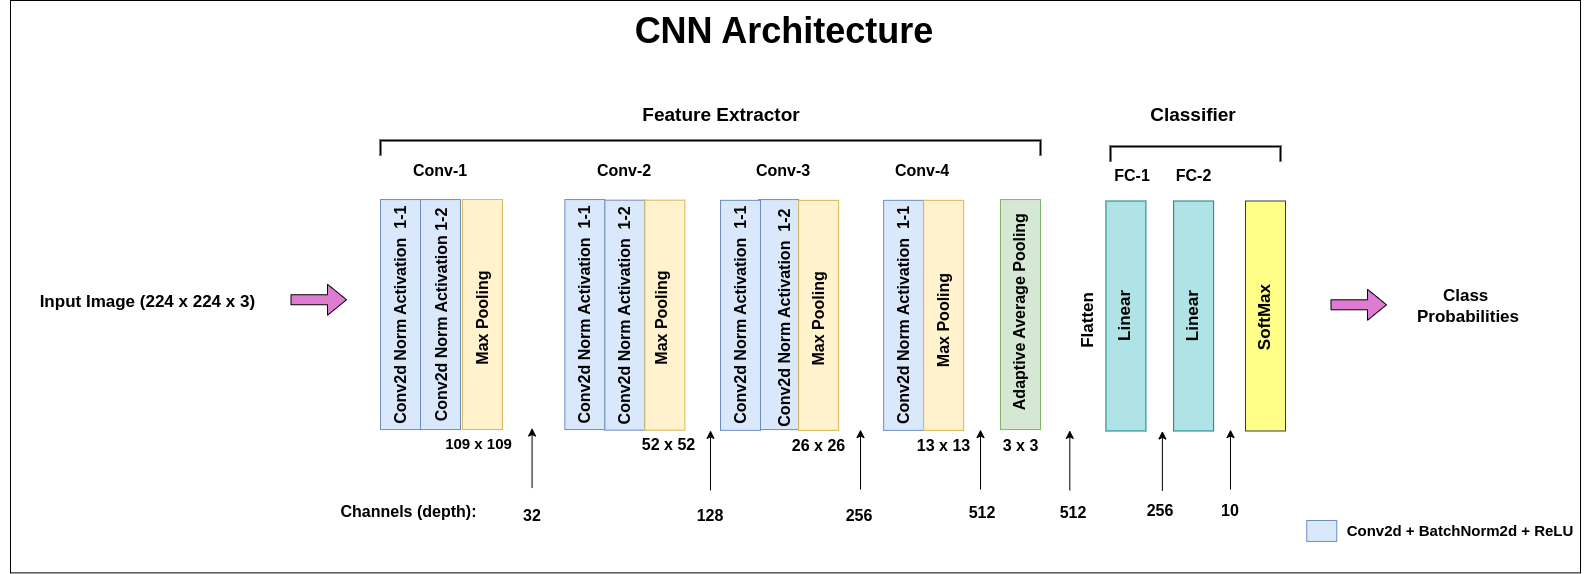

In [15]:
class MyModel(nn.Module):
  def __init__(self):
    super().__init__()

    self._model = nn.Sequential(

        #---------------------- Convolution Layers ----------------------

        #-----------------------------------------------
        # Conv2d Norm Activation Block1: 32 Filters, MaxPool.
        #-----------------------------------------------
        nn.Conv2d(in_channels = 3, out_channels = 32, kernel_size = 5),
        nn.BatchNorm2d(32),
        nn.ReLU(inplace = True),

        nn.Conv2d(in_channels = 32, out_channels = 32, kernel_size = 3),
        nn.BatchNorm2d(32),
        nn.ReLU(inplace = True),
        nn.MaxPool2d(kernel_size = 2),

        #-------------------------------------------------------------------
        # Conv2d Norm Activation Block 2: 64,128 Filters, MaxPool, Dropout(p=0.25)
        #-------------------------------------------------------------------
        nn.LazyConv2d(out_channels = 64, kernel_size = 3),
        nn.BatchNorm2d(64),
        nn.ReLU(inplace = True),

        nn.LazyConv2d(out_channels = 128, kernel_size = 3),
        nn.BatchNorm2d(128),
        nn.ReLU(inplace = True),
        nn.MaxPool2d(kernel_size = 2),

        #--------------------------------------------------
        # Conv2d Norm Activation Block 3: 128,256,512 Filters, MaxPool.
        #--------------------------------------------------
        Conv2dNormActivation(in_channels = 128, out_channels=256, kernel_size = 3),

        Conv2dNormActivation(in_channels = 256, out_channels=256, kernel_size = 3),
        nn.MaxPool2d(kernel_size = 2),

        Conv2dNormActivation(in_channels = 256, out_channels=512, kernel_size = 3),
        nn.MaxPool2d(kernel_size = 2),

        #---------------------- Feed Forward Layers --------------------
        nn.AdaptiveAvgPool2d(output_size=(3,3)),

        #------------------------------------
        # Flatten the convolutional features.
        #------------------------------------
        nn.Flatten(),

        #--------------------
        # Classification Head.
        #--------------------
        nn.Linear(in_features = 512*3*3, out_features = 256),
        nn.Linear(in_features = 256, out_features = 10)
    )

  def forward(self,x):
      return self._model(x)


In [16]:
model = MyModel()
optimizer = Adam(model.parameters(), lr = train_config.learning_rate)
DEVICE = torch.device("cuda") if torch.cuda.is_available() else "cpu"

logdir = "runs/80epochs-3.3M_param_dropout"

writer = SummaryWriter(logdir)

In [17]:
def train(model, train_loader):
  model.train()
  model.to(DEVICE)

  running_loss = 0
  correct_predictions = 0
  total_train_samples = 0

  for images, labels in tqdm(train_loader, desc="Training"):
    images, labels = images.to(DEVICE), labels.to(DEVICE)
    optimizer.zero_grad()
    outputs = model(images)
    loss = F.cross_entropy(outputs, labels)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    _, predicted = torch.max(outputs.data, dim = 1)
    total_train_samples += labels.shape[0]
    correct_predictions += (predicted == labels).sum().item()

  train_avg_loss = running_loss/ len(train_loader)
  train_accuracy = 100 * (correct_predictions/ total_train_samples)
  return train_avg_loss, train_accuracy


In [18]:
def validation(model, val_loader):
  model.eval()
  model.to(DEVICE)

  running_loss = 0
  correct_predictions = 0
  total_train_samples = 0

  for images, labels in tqdm(val_loader, desc="Validation"):
    images, labels = images.to(DEVICE), labels.to(DEVICE)

    with torch.no_grad():
      outputs = model(images)

    loss = F.cross_entropy(outputs, labels)
    running_loss += loss.item()
    _, predicted = torch.max(outputs.data, dim = 1)
    total_train_samples += labels.shape[0]
    correct_predictions += (predicted == labels).sum().item()

  val_avg_loss = running_loss/ len(train_loader)
  val_accuracy = 100 * (correct_predictions/ total_train_samples)
  return val_avg_loss, val_accuracy

In [19]:
def main(model, train_loader, val_loader):

    train_losses, val_losses = [], []
    train_accuracies, val_accuracies = [], []

    best_val_acc = 0.0
    best_weights = None

    for epoch in range(train_config.num_epochs):
        train_loss, train_accuracy = train(model, train_loader)
        val_loss, val_accuracy = validation(model, val_loader)


        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        print(f"Epoch {epoch+1:0>2}/{train_config.num_epochs} - Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}% - Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.2f}%")

        # Logging metrics to tensorboard
        writer.add_scalar('Loss/train', train_loss)
        writer.add_scalar('Loss/val', val_loss)
        writer.add_scalar('Accuracy/train', train_accuracy)
        writer.add_scalar('Accuracy/val', val_accuracy)

        if val_accuracy > best_val_acc:
            best_val_acc = val_accuracy
            best_weights =  model.state_dict()
            print(f"Saving best model...💾")
            torch.save(best_weights, "best.pt")

    return train_losses, train_accuracies, val_losses, val_accuracies

In [20]:
train_losses, train_accuracies, val_losses, val_accuracies = main(model, train_loader, val_loader)

Validation: 100%|██████████| 9/9 [00:06<00:00,  1.40it/s]


Epoch 01/50 - Train Loss: 1.9332, Train Accuracy: 30.17% - Val Loss: 0.4562, Val Accuracy: 32.35%
Saving best model...💾


Validation: 100%|██████████| 9/9 [00:06<00:00,  1.36it/s]


Epoch 02/50 - Train Loss: 1.4513, Train Accuracy: 49.41% - Val Loss: 0.3408, Val Accuracy: 52.94%
Saving best model...💾


Validation: 100%|██████████| 9/9 [00:06<00:00,  1.48it/s]


...

Epoch 48/50 - Train Loss: 0.3306, Train Accuracy: 88.61% - Val Loss: 0.2496, Val Accuracy: 73.16%


Validation: 100%|██████████| 9/9 [00:06<00:00,  1.33it/s]


Epoch 49/50 - Train Loss: 0.2693, Train Accuracy: 90.43% - Val Loss: 0.2305, Val Accuracy: 76.84%


Validation: 100%|██████████| 9/9 [00:05<00:00,  1.57it/s]

Epoch 50/50 - Train Loss: 0.2687, Train Accuracy: 92.07% - Val Loss: 0.2106, Val Accuracy: 75.37%


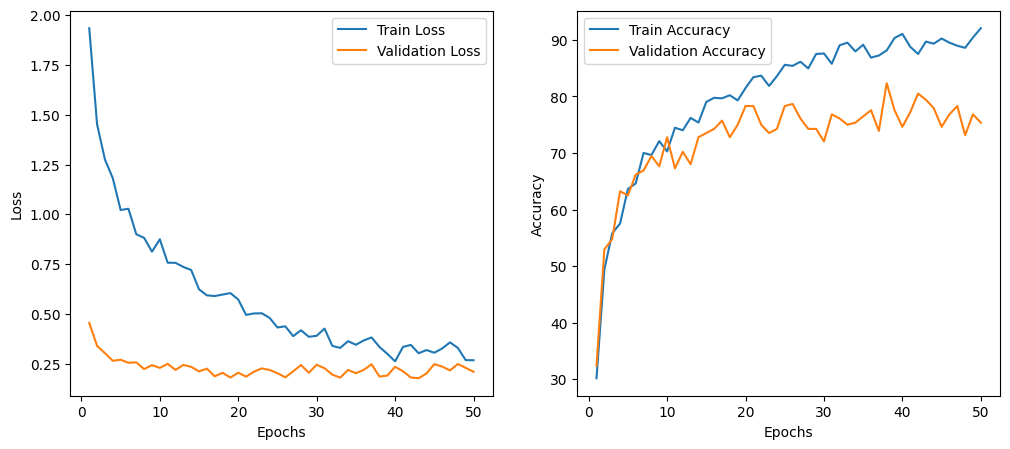

In [21]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(range(1,train_config.num_epochs + 1), train_losses, label = "Train Loss")
plt.plot(range(1, train_config.num_epochs + 1), val_losses, label = "Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(range(1,train_config.num_epochs + 1), train_accuracies, label = "Train Accuracy")
plt.plot(range(1, train_config.num_epochs + 1), val_accuracies, label = "Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()